In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DT, SIM_TIME, VEHICLE_LENGTH, MIN_GAP,
    HDV_ACCEL_MIN, HDV_ACCEL_MAX, HDV_SPEED_MAX,
    AV_ACCEL_MIN, AV_ACCEL_MAX, AV_SPEED_MAX,
)

FIG_WIDTH = 12
FIG_HEIGHT = 3

print(f"DT = {DT} s")
print(f"Simulation time = {SIM_TIME} s")
print(f"Vehicle length = {VEHICLE_LENGTH} m")
print(f"Minimum gap = {MIN_GAP} m")

DT = 0.1 s
Simulation time = 60.0 s
Vehicle length = 4.5 m
Minimum gap = 2.0 m


In [2]:
from src.dataloader import load_data

df = load_data()

print("Initial traffic configuration:")
display(df)
print(f"\nNumber of vehicles: {len(df)}")
print("Vehicle types:")
print(df["type"].value_counts())

Initial traffic configuration:


,vehicle_id,position_m,speed_mps,type
0,0,199.50,13.83,HDV
1,1,187.52,15.04,HDV
2,2,172.36,17.25,HDV
3,3,157.54,16.32,HDV
4,4,141.48,14.91,HDV
5,5,127.20,18.12,HDV
6,6,112.52,13.39,HDV
7,7,101.46,14.92,AV
8,8,86.12,15.66,HDV
9,9,72.26,16.56,HDV



Number of vehicles: 15
Vehicle types:
type
HDV    11
AV      4
Name: count, dtype: int64


In [3]:
from src.dynamics import calculate_gap, HDVDynamics

# Use the same gap calculation as the simulation.
df["gap_m"] = np.nan

for i in range(1, len(df)):
    df.loc[i, "gap_m"] = calculate_gap(
        df.loc[i - 1, "position_m"],
        df.loc[i, "position_m"]
    )

print(df[["vehicle_id", "position_m", "speed_mps", "type", "gap_m"]].to_string(index=False))


 vehicle_id  position_m  speed_mps type  gap_m
          0      199.50      13.83  HDV    NaN
          1      187.52      15.04  HDV   7.48
          2      172.36      17.25  HDV  10.66
          3      157.54      16.32  HDV  10.32
          4      141.48      14.91  HDV  11.56
          5      127.20      18.12  HDV   9.78
          6      112.52      13.39  HDV  10.18
          7      101.46      14.92   AV   6.56
          8       86.12      15.66  HDV  10.84
          9       72.26      16.56  HDV   9.36
         10       55.23      19.85   AV  12.53
         11       44.74      14.00  HDV   5.99
         12       29.90      17.14   AV  10.34
         13       13.14      17.92  HDV  12.26
         14       -1.27      12.46   AV   9.91


In [4]:
valid_gaps = df["gap_m"].dropna()

if (valid_gaps <= 0).any():
    print("WARNING: At least one vehicle has a non-positive initial gap.")
else:
    print("All initial vehicle gaps are positive.")

print(f"Minimum initial gap: {valid_gaps.min():.2f} m")
print(f"Mean initial gap:    {valid_gaps.mean():.2f} m")
print(f"Maximum initial gap: {valid_gaps.max():.2f} m")


All initial vehicle gaps are positive.
Minimum initial gap: 5.99 m
Mean initial gap:    9.84 m
Maximum initial gap: 12.53 m


In [5]:
# Initial HDV accelerations using the same model as src.dynamics.
df["initial_accel_mps2"] = np.nan

for i in range(1, len(df)):
    if df.loc[i, "type"] == "HDV":
        df.loc[i, "initial_accel_mps2"] = HDVDynamics.calculate_acceleration(
            df.loc[i, "speed_mps"],
            df.loc[i - 1, "speed_mps"],
            df.loc[i, "gap_m"]
        )

display(df[[
    "vehicle_id", "type", "position_m", "speed_mps",
    "gap_m", "initial_accel_mps2"
]])

hdv_acc = df["initial_accel_mps2"].dropna()
if not hdv_acc.empty:
    print(f"Minimum HDV acceleration: {hdv_acc.min():.2f} m/s²")
    print(f"Maximum HDV acceleration: {hdv_acc.max():.2f} m/s²")


,vehicle_id,type,position_m,speed_mps,gap_m,initial_accel_mps2
0,0,HDV,199.50,13.83,NaN,NaN
1,1,HDV,187.52,15.04,7.48,-1.109
2,2,HDV,172.36,17.25,10.66,-0.973
3,3,HDV,157.54,16.32,10.32,0.529
4,4,HDV,141.48,14.91,11.56,1.017
5,5,HDV,127.20,18.12,9.78,-1.649
6,6,HDV,112.52,13.39,10.18,2.000
7,7,AV,101.46,14.92,6.56,NaN
8,8,HDV,86.12,15.66,10.84,-0.202
9,9,HDV,72.26,16.56,9.36,-0.578


Minimum HDV acceleration: -1.65 m/s²
Maximum HDV acceleration: 2.00 m/s²


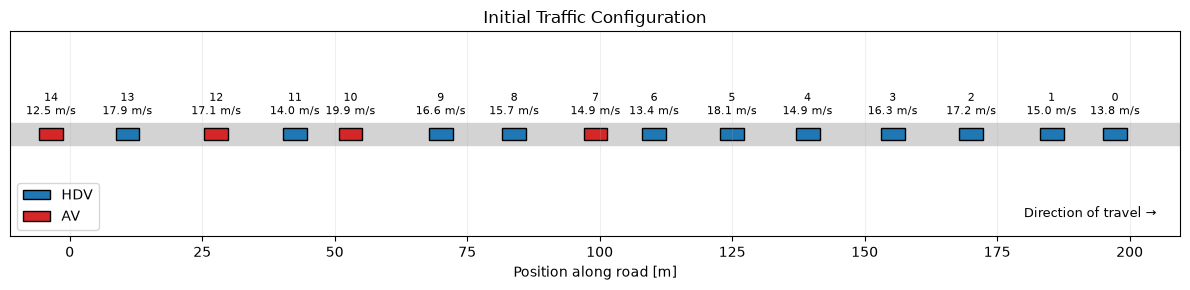

In [6]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

VEHICLE_HEIGHT = 0.2
ROAD_Y = 0.0 # Y-coordinate of the road
ROAD_HEIGHT = VEHICLE_HEIGHT + 0.2

# Road
ax.add_patch(
    plt.Rectangle(
        (df["position_m"].min() - 10, -ROAD_HEIGHT / 2),         # bottom-left corner of the road
        df["position_m"].max() - df["position_m"].min() + 20,    # length of the road in x 
        ROAD_HEIGHT,                                             # width of the road in y
        facecolor="lightgray",
        edgecolor="lightgray",
        linewidth=1.0
    )
)

# Vehicles
for _, row in df.iterrows():
    x = row["position_m"]
    facecolor = "tab:red" if row["type"] == "AV" else "tab:blue"
    ax.add_patch(
        plt.Rectangle(
            (x - VEHICLE_LENGTH, ROAD_Y - VEHICLE_HEIGHT / 2), # bottom-left corner of the vehicle bounding box
            VEHICLE_LENGTH,
            VEHICLE_HEIGHT,
            facecolor=facecolor,
            edgecolor="black",
            linewidth=1.0
        )
    )

    ax.text(
        x - VEHICLE_LENGTH / 2,
        VEHICLE_HEIGHT / 2 + 0.18,
        f"{int(row['vehicle_id'])}\n"
        f"{row['speed_mps']:.1f} m/s",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Direction
ax.text(
    0.98, 0.08,
    "Direction of travel →",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9
)

# Axes
ax.set_xlim(
    df["position_m"].min() - 10,
    df["position_m"].max() + 10
)

ax.set_ylim(-1.8, 1.8)

ax.set_xlabel("Position along road [m]")
ax.set_yticks([])


ax.set_title("Initial Traffic Configuration")

ax.grid(axis="x", alpha=0.2)

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="tab:blue", edgecolor="black", label="HDV"),
    Patch(facecolor="tab:red", edgecolor="black", label="AV")
]

ax.legend(
    handles=legend_elements,
    loc="lower left"
)

plt.tight_layout()
plt.show()

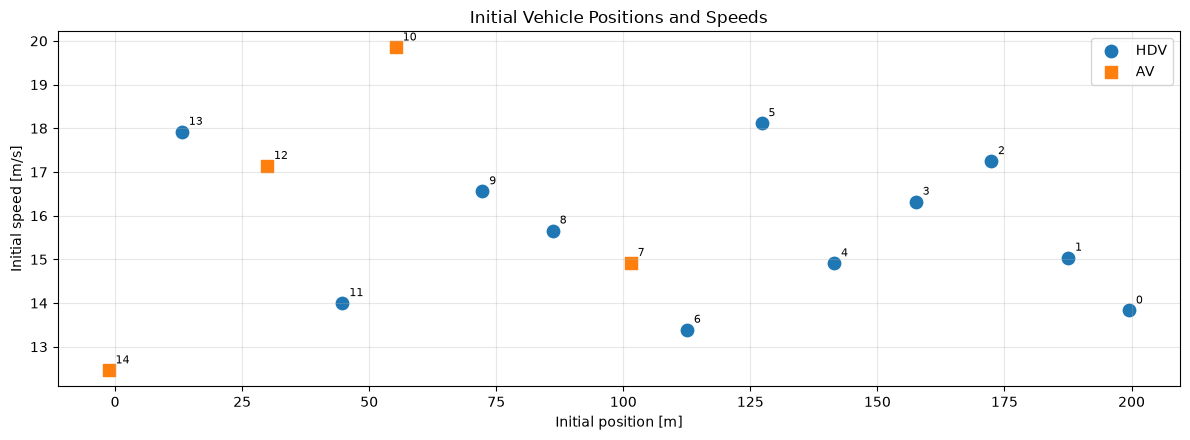

In [7]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.5))

for vehicle_type, marker, label in [
    ("HDV", "o", "HDV"),
    ("AV", "s", "AV"),
]:
    subset = df[df["type"] == vehicle_type]
    ax.scatter(
        subset["position_m"], subset["speed_mps"],
        marker=marker, s=80, label=label
    )

    for _, row in subset.iterrows():
        ax.annotate(
            int(row["vehicle_id"]),
            (row["position_m"], row["speed_mps"]),
            xytext=(5, 5), textcoords="offset points", fontsize=8
        )

ax.set_xlabel("Initial position [m]")
ax.set_ylabel("Initial speed [m/s]")
ax.set_title("Initial Vehicle Positions and Speeds")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
from src.simulation_without_ped import simulate

# Run the updated mixed-traffic simulation.
results = simulate(df)

time = results["time"]
positions = results["positions"]
speeds = results["speeds"]
accelerations = results["accelerations"]
gaps = results["gaps"]
vehicle_types = results["vehicle_types"]

print(f"Simulation steps: {len(time)}")
print(f"Simulation duration: {time[-1]:.1f} s")
print(f"Vehicles: {positions.shape[1]}")
print("Vehicle types:", vehicle_types)

Simulation steps: 601
Simulation duration: 60.0 s
Vehicles: 15
Vehicle types: ['HDV' 'HDV' 'HDV' 'HDV' 'HDV' 'HDV' 'HDV' 'AV' 'HDV' 'HDV' 'AV' 'HDV'
 'AV' 'HDV' 'AV']


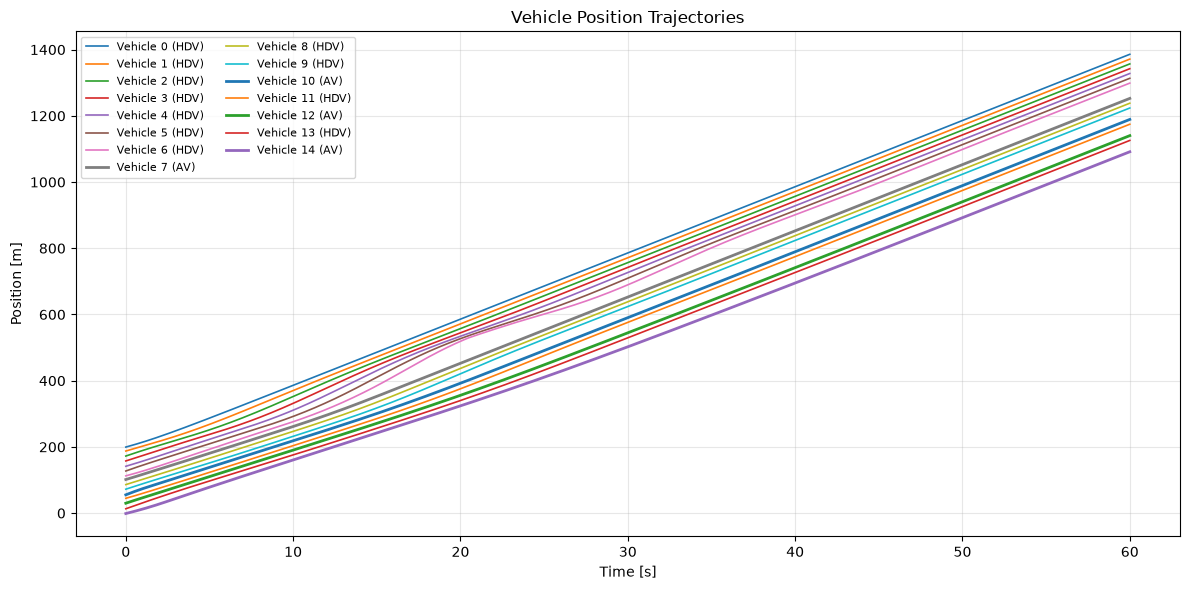

In [9]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6))

for i in range(positions.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    vehicle_type = vehicle_types[i]

    ax.plot(
        time, positions[:, i],
        label=f"Vehicle {vehicle_id} ({vehicle_type})",
        linewidth=2 if vehicle_type == "AV" else 1.2,
    )

ax.set_xlabel("Time [s]")
ax.set_ylabel("Position [m]")
ax.set_title("Vehicle Position Trajectories")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

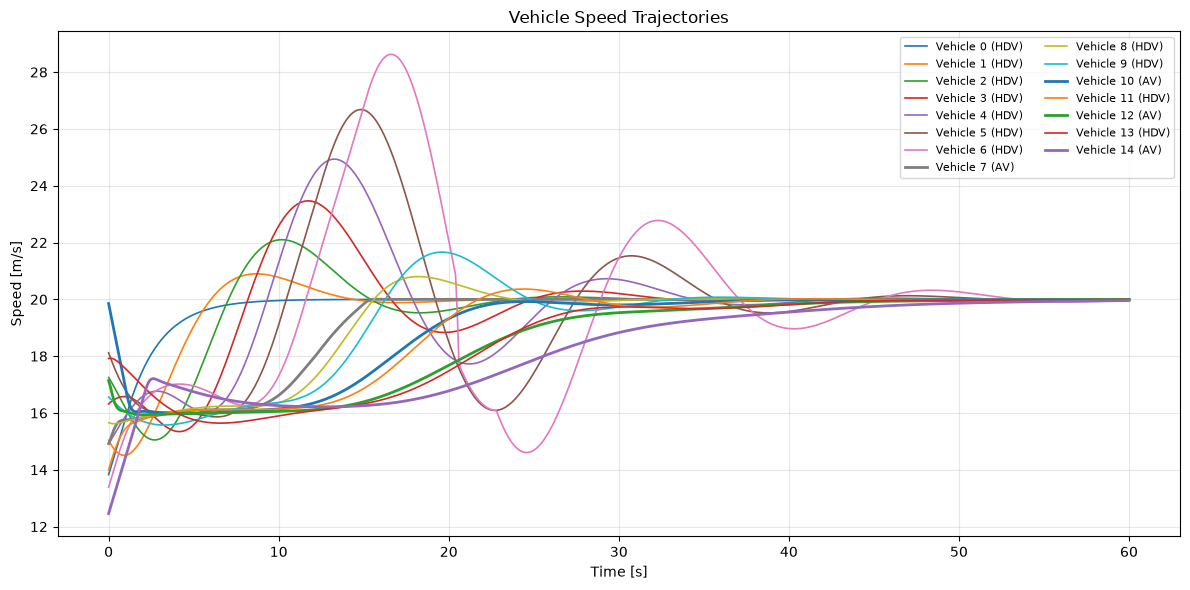

In [10]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6))

for i in range(speeds.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    vehicle_type = vehicle_types[i]

    ax.plot(
        time, speeds[:, i],
        label=f"Vehicle {vehicle_id} ({vehicle_type})",
        linewidth=2 if vehicle_type == "AV" else 1.2,
    )

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Vehicle Speed Trajectories")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# Safety and physical checks
ordering_ok = np.all(positions[:, :-1] > positions[:, 1:], axis=1)

print("Vehicle ordering maintained:", ordering_ok.all())

if not ordering_ok.all():
    first_bad = np.where(~ordering_ok)[0][0]
    print(f"First ordering violation: t = {time[first_bad]:.1f} s")

minimum_gap = np.nanmin(gaps)
idx = np.unravel_index(np.nanargmin(gaps), gaps.shape)

print(f"Minimum simulated gap: {minimum_gap:.3f} m")
print(f"Minimum gap occurs at t = {time[idx[0]]:.1f} s, vehicle index = {idx[1]}")
print(f"Required minimum gap: {MIN_GAP:.3f} m")

print(f"Maximum speed: {speeds.max():.3f} m/s")
print(f"Minimum speed: {speeds.min():.3f} m/s")
print(f"Number of zero-speed states: {np.sum(speeds <= 0.0)}")

Vehicle ordering maintained: True
Minimum simulated gap: 2.000 m
Minimum gap occurs at t = 20.5 s, vehicle index = 6
Required minimum gap: 2.000 m
Maximum speed: 28.627 m/s
Minimum speed: 12.460 m/s
Number of zero-speed states: 0


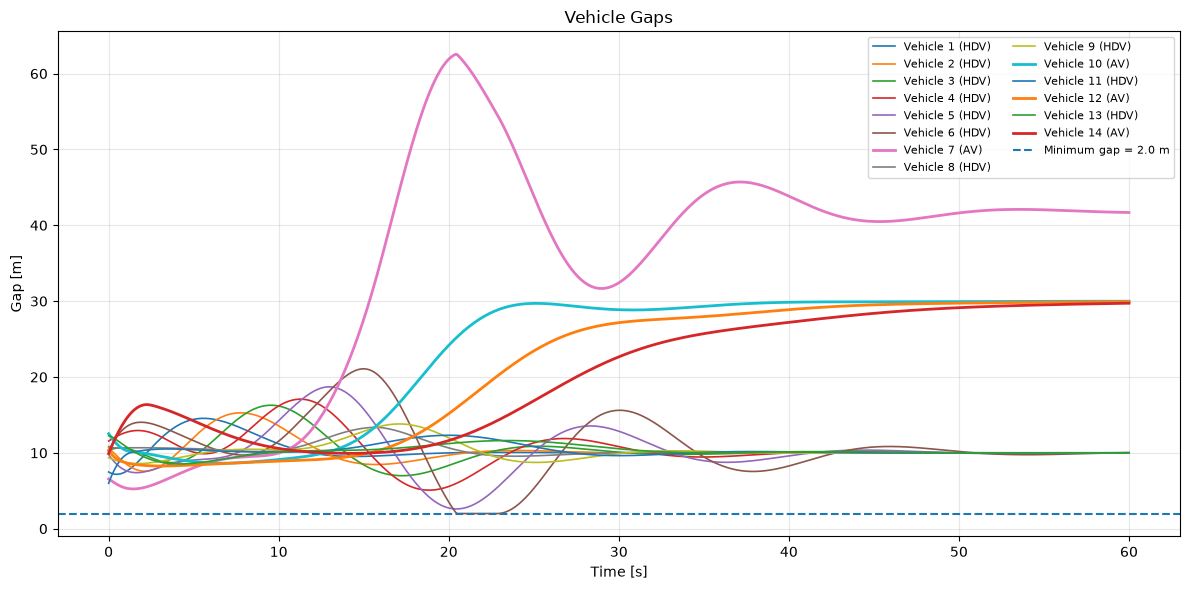

In [12]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6))

for i in range(1, gaps.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    vehicle_type = vehicle_types[i]

    ax.plot(
        time, gaps[:, i],
        label=f"Vehicle {vehicle_id} ({vehicle_type})",
        linewidth=2 if vehicle_type == "AV" else 1.2,
    )

ax.axhline(
    MIN_GAP, linestyle="--", linewidth=1.5,
    label=f"Minimum gap = {MIN_GAP} m"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Gap [m]")
ax.set_title("Vehicle Gaps")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

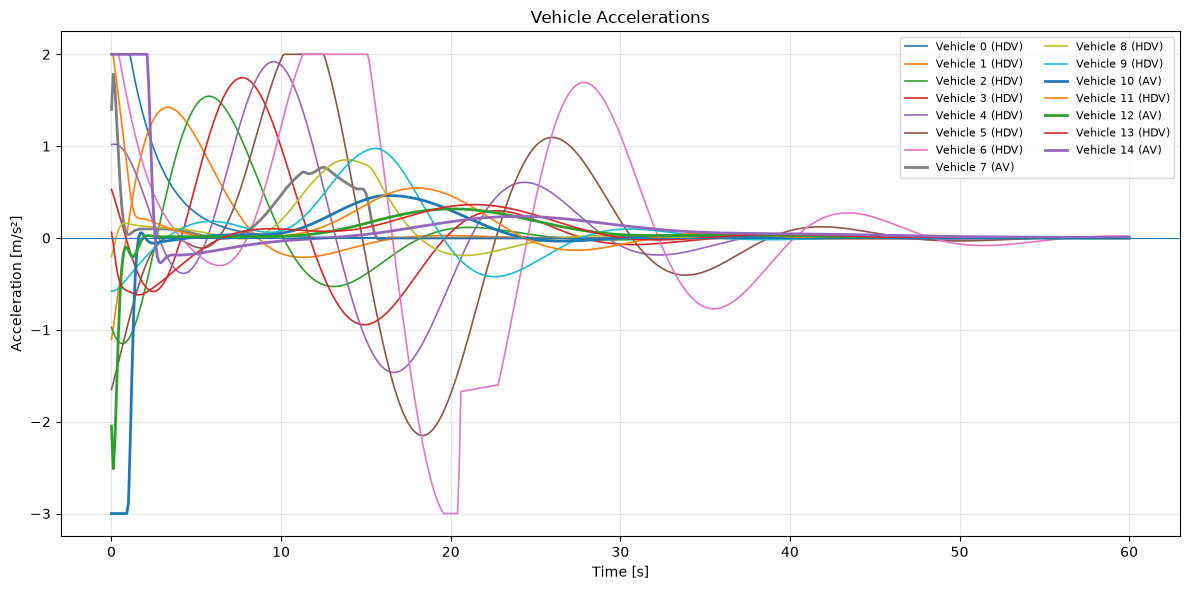

In [13]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6))

for i in range(accelerations.shape[1]):
    vehicle_id = int(df.iloc[i]["vehicle_id"])
    vehicle_type = vehicle_types[i]

    ax.plot(
        time, accelerations[:, i],
        label=f"Vehicle {vehicle_id} ({vehicle_type})",
        linewidth=2 if vehicle_type == "AV" else 1.2,
    )

ax.axhline(0, linewidth=0.8)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Acceleration [m/s²]")
ax.set_title("Vehicle Accelerations")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


In [14]:
summary = pd.DataFrame({
    "vehicle_id": df["vehicle_id"].astype(int),
    "type": vehicle_types,
    "max_speed_mps": np.max(speeds, axis=0),
    "min_speed_mps": np.min(speeds, axis=0),
    "max_accel_mps2": np.max(accelerations, axis=0),
    "min_accel_mps2": np.min(accelerations, axis=0),
    "min_gap_m": [
        np.nanmin(gaps[:, i]) if i > 0 else np.nan
        for i in range(len(vehicle_types))
    ],
})

display(summary)

,vehicle_id,type,max_speed_mps,min_speed_mps,max_accel_mps2,min_accel_mps2,min_gap_m
0,0,HDV,20.000000,13.830000,2.000000,1.509903e-13,NaN
1,1,HDV,20.898143,14.508578,1.422298,-1.109000e+00,7.172795
2,2,HDV,22.100676,15.050385,1.543285,-1.148666e+00,7.586062
3,3,HDV,23.466700,15.345790,1.745316,-9.443315e-01,6.987255
4,4,HDV,24.936804,14.910000,1.919714,-1.463587e+00,5.083044
5,5,HDV,26.681108,15.862445,2.000000,-2.149921e+00,2.606345
6,6,HDV,28.627102,13.390000,2.000000,-3.000000e+00,2.000000
7,7,AV,20.006689,14.920000,1.784635,-1.769406e-02,5.243888
8,8,HDV,20.801261,15.620905,0.851359,-2.020000e-01,9.558153
9,9,HDV,21.663327,15.576017,0.974607,-5.780000e-01,8.583310


In [15]:
# -------------------------------------------------
# AV time-headway diagnostic
# -------------------------------------------------

from src.config import AV_HEADWAY_TARGET, AV_EPSILON

time = results["time"]
gaps = results["gaps"]
speeds = results["speeds"]
vehicle_types = results["vehicle_types"]

av_indices = np.where(vehicle_types == "AV")[0]

print("===== AV TIME-HEADWAY DIAGNOSTIC =====")

for i in av_indices:

    valid = gaps[:, i] > 0

    headway = np.full_like(time, np.nan, dtype=float)

    headway[valid] = (
        gaps[valid, i]
        / np.maximum(speeds[valid, i], AV_EPSILON)
    )

    k = np.nanargmin(headway)

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    print(
        f"Vehicle {vehicle_id}: "
        f"min = {headway[k]:.3f} s "
        f"at t = {time[k]:.1f} s, "
        f"gap = {gaps[k, i]:.3f} m, "
        f"speed = {speeds[k, i]:.3f} m/s, "
        f"mean = {np.nanmean(headway):.3f} s, "
        f"final = {headway[-1]:.3f} s"
    )

===== AV TIME-HEADWAY DIAGNOSTIC =====
Vehicle 7: min = 0.332 s at t = 1.5 s, gap = 5.244 m, speed = 15.785 m/s, mean = 1.764 s, final = 2.084 s
Vehicle 10: min = 0.538 s at t = 6.8 s, gap = 8.631 m, speed = 16.029 m/s, mean = 1.213 s, final = 1.500 s
Vehicle 12: min = 0.518 s at t = 3.2 s, gap = 8.268 m, speed = 15.957 m/s, mean = 1.127 s, final = 1.497 s
Vehicle 14: min = 0.612 s at t = 14.4 s, gap = 9.935 m, speed = 16.238 m/s, mean = 1.108 s, final = 1.489 s


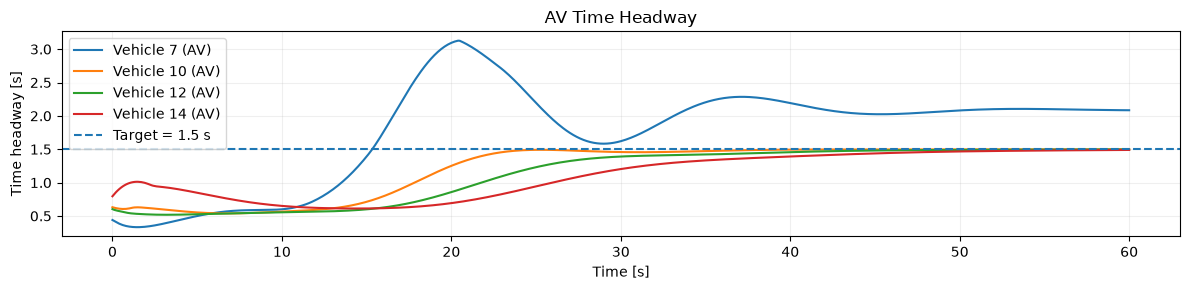

In [16]:
# -------------------------------------------------
# AV time-headway plot
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

for i in av_indices:

    valid = gaps[:, i] > 0

    headway = np.full_like(time, np.nan, dtype=float)

    headway[valid] = (
        gaps[valid, i]
        / np.maximum(speeds[valid, i], AV_EPSILON)
    )

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    ax.plot(
        time,
        headway,
        label=f"Vehicle {vehicle_id} (AV)"
    )

ax.axhline(
    AV_HEADWAY_TARGET,
    linestyle="--",
    label=f"Target = {AV_HEADWAY_TARGET:.1f} s"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Time headway [s]")
ax.set_title("AV Time Headway")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

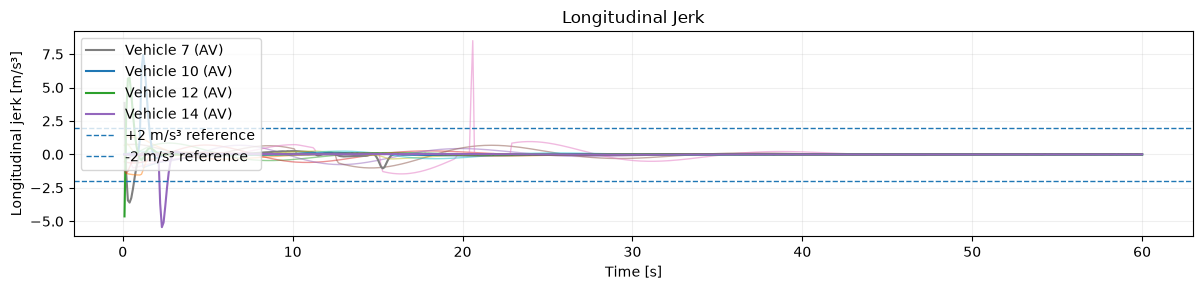

In [17]:
# -------------------------------------------------
# Longitudinal jerk
# -------------------------------------------------

# Jerk is the rate of change of acceleration
jerk = np.diff(accelerations, axis=0) / DT

# Jerk has one fewer sample than acceleration
jerk_time = time[1:]

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

for i in range(len(vehicle_types)):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    if vehicle_types[i] == "AV":
        ax.plot(
            jerk_time,
            jerk[:, i],
            label=f"Vehicle {vehicle_id} (AV)",
            linewidth=1.5
        )
    else:
        ax.plot(
            jerk_time,
            jerk[:, i],
            alpha=0.5,
            linewidth=1.0
        )

# Comfort reference limits
ax.axhline(
    2.0,
    linestyle="--",
    linewidth=1.0,
    label="+2 m/s³ reference"
)

ax.axhline(
    -2.0,
    linestyle="--",
    linewidth=1.0,
    label="-2 m/s³ reference"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Longitudinal jerk [m/s³]")
ax.set_title("Longitudinal Jerk")

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [18]:
print("===== LONGITUDINAL JERK SUMMARY =====")

for i in range(len(vehicle_types)):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    abs_jerk = np.abs(jerk[:, i])

    print(
        f"Vehicle {vehicle_id} ({vehicle_types[i]}): "
        f"max |jerk| = {np.max(abs_jerk):.2f} m/s³, "
        f"mean |jerk| = {np.mean(abs_jerk):.2f} m/s³, "
        f"above 2 m/s³ = "
        f"{100 * np.mean(abs_jerk > 2):.1f}%"
    )

===== LONGITUDINAL JERK SUMMARY =====
Vehicle 0 (HDV): max |jerk| = 0.99 m/s³, mean |jerk| = 0.03 m/s³, above 2 m/s³ = 0.0%
Vehicle 1 (HDV): max |jerk| = 1.31 m/s³, mean |jerk| = 0.07 m/s³, above 2 m/s³ = 0.0%
Vehicle 2 (HDV): max |jerk| = 0.85 m/s³, mean |jerk| = 0.10 m/s³, above 2 m/s³ = 0.0%
Vehicle 3 (HDV): max |jerk| = 0.70 m/s³, mean |jerk| = 0.13 m/s³, above 2 m/s³ = 0.0%
Vehicle 4 (HDV): max |jerk| = 0.76 m/s³, mean |jerk| = 0.17 m/s³, above 2 m/s³ = 0.0%
Vehicle 5 (HDV): max |jerk| = 1.01 m/s³, mean |jerk| = 0.23 m/s³, above 2 m/s³ = 0.0%
Vehicle 6 (HDV): max |jerk| = 8.50 m/s³, mean |jerk| = 0.30 m/s³, above 2 m/s³ = 0.3%
Vehicle 7 (AV): max |jerk| = 3.85 m/s³, mean |jerk| = 0.07 m/s³, above 2 m/s³ = 0.8%
Vehicle 8 (HDV): max |jerk| = 0.84 m/s³, mean |jerk| = 0.04 m/s³, above 2 m/s³ = 0.0%
Vehicle 9 (HDV): max |jerk| = 0.32 m/s³, mean |jerk| = 0.06 m/s³, above 2 m/s³ = 0.0%
Vehicle 10 (AV): max |jerk| = 7.44 m/s³, mean |jerk| = 0.07 m/s³, above 2 m/s³ = 0.8%
Vehicle 11 (HDV):